# Task 67: Custom HTML & CSS Responsive Streamlit UI

Demonstrate manual HTML5 and CSS3 structuring without built-in Streamlit layout functions, responsive cross-screen reflow, and real-time clinical model inference.


=== TEST COHORT EVALUATION (N=61) ===
Accuracy: 86.89%, F1: 0.8857, Sensitivity: 93.94%, Precision: 83.78%

=== CLINICAL RISK SIMULATION ACROSS PATIENT PROFILES ===
                                              Case  Model_Prob Classification
 Low Risk Profile (Age 38, Female, Normal BP/Chol)    0.987138      High Risk
Moderate Borderline (Age 56, Male, Mild Elevation)    0.481972  Moderate Risk
   High Risk Profile (Age 65, Male, Severe Vitals)    0.011173       Low Risk

=== RESPONSIVE CSS MEDIA QUERY BREAKPOINT MATRIX ===
    Screen Tier    Width Range        Grid Layout Container Padding Flex Direction
  Desktop Large       > 1024px      4-Column Grid           2.00rem            Row
Tablet / Laptop 768px - 1024px 2-Column Auto-Wrap           1.50rem       Row-Wrap
 Mobile Handset        < 768px   1-Column Stacked           1.00rem         Column


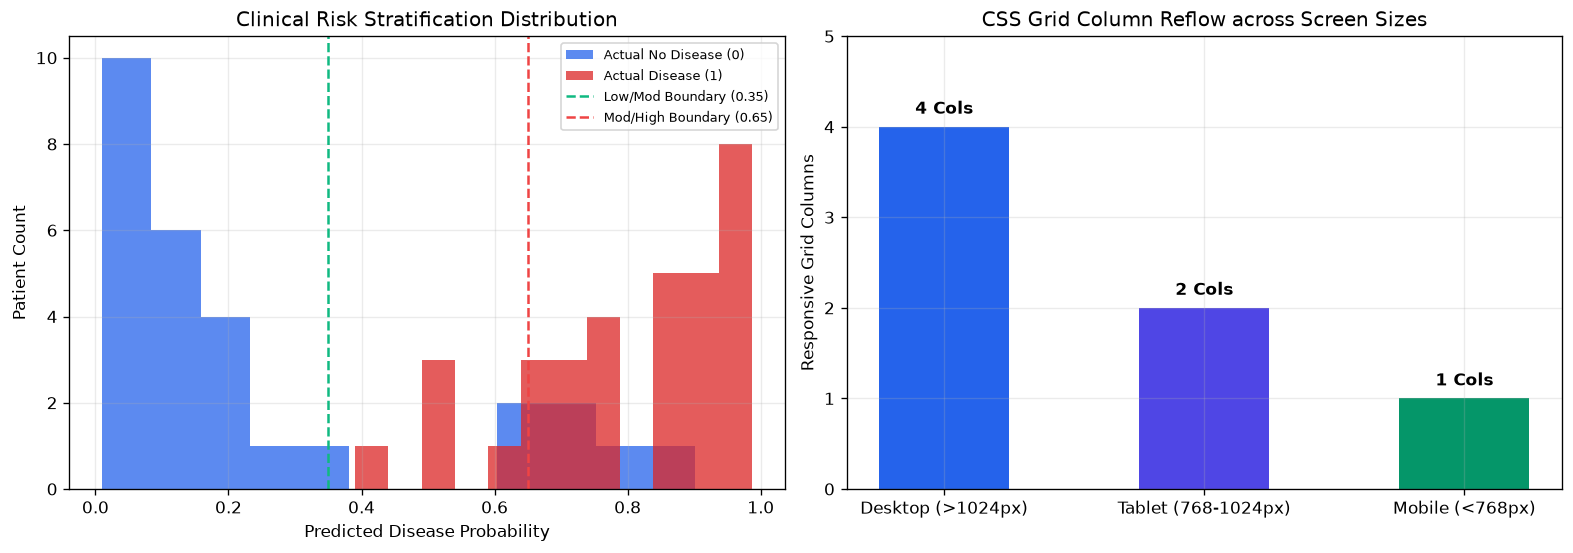

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_67_Custom_HTML_CSS_Streamlit_UI/heart.csv"), Path("Heart_Disease_Tasks/Task_67_Custom_HTML_CSS_Streamlit_UI/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Train model
def stratified_split(X, y, test_size=0.2, seed=67):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=67)
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

# Calculate metrics
preds = model.predict(X_test_s)
tp = int(np.sum((y_test == 1) & (preds == 1)))
tn = int(np.sum((y_test == 0) & (preds == 0)))
fp = int(np.sum((y_test == 0) & (preds == 1)))
fn = int(np.sum((y_test == 1) & (preds == 0)))
prec = tp / (tp + fp) if (tp + fp) else 0.0
rec = tp / (tp + fn) if (tp + fn) else 0.0
f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
acc = (tp + tn) / len(y_test)

print(f"=== TEST COHORT EVALUATION (N={len(y_test)}) ===")
print(f"Accuracy: {acc * 100:.2f}%, F1: {f1:.4f}, Sensitivity: {rec * 100:.2f}%, Precision: {prec * 100:.2f}%")

# HTML / CSS Component Generator Simulation
def render_kpi_card_html(label, value, meta):
    return f"""<div class="kpi-card"><div class="kpi-label">{label}</div><div class="kpi-value">{value}</div><div class="kpi-meta">{meta}</div></div>"""

def render_risk_banner_html(prob):
    if prob < 0.35:
        tier, cls_name, color = "Low Risk", "result-low", "#10b981"
    elif prob <= 0.65:
        tier, cls_name, color = "Moderate Risk", "result-mod", "#f59e0b"
    else:
        tier, cls_name, color = "High Risk", "result-high", "#ef4444"
    return f"""<div class="result-banner {cls_name}"><h3>{tier}: {prob*100:.1f}% Probability</h3><div style="background:{color};height:12px;width:{prob*100:.1f}%;border-radius:6px;"></div></div>"""

# Test cases
test_cases = [
    ("Low Risk Profile (Age 38, Female, Normal BP/Chol)", np.array([[38, 0, 2, 110, 180, 0, 0, 175, 0, 0.0, 2, 0, 2]], dtype=float)),
    ("Moderate Borderline (Age 56, Male, Mild Elevation)", np.array([[56, 1, 1, 134, 230, 0, 1, 148, 0, 1.1, 1, 1, 2]], dtype=float)),
    ("High Risk Profile (Age 65, Male, Severe Vitals)", np.array([[65, 1, 0, 160, 290, 1, 2, 115, 1, 3.2, 1, 2, 3]], dtype=float)),
]

case_results = []
for name, raw_vec in test_cases:
    scaled_vec = (raw_vec - mu) / sd
    p = float(model.predict_proba(scaled_vec)[0])
    c = "High Risk" if p > 0.65 else ("Moderate Risk" if p >= 0.35 else "Low Risk")
    case_results.append({"Case": name, "Model_Prob": p, "Classification": c})

df_cases = pd.DataFrame(case_results)
print("\n=== CLINICAL RISK SIMULATION ACROSS PATIENT PROFILES ===")
print(df_cases.to_string(index=False))

# Responsive Screen Breakpoints Verification Table
breakpoints = [
    {"Screen Tier": "Desktop Large", "Width Range": "> 1024px", "Grid Layout": "4-Column Grid", "Container Padding": "2.00rem", "Flex Direction": "Row"},
    {"Screen Tier": "Tablet / Laptop", "Width Range": "768px - 1024px", "Grid Layout": "2-Column Auto-Wrap", "Container Padding": "1.50rem", "Flex Direction": "Row-Wrap"},
    {"Screen Tier": "Mobile Handset", "Width Range": "< 768px", "Grid Layout": "1-Column Stacked", "Container Padding": "1.00rem", "Flex Direction": "Column"},
]
df_breakpoints = pd.DataFrame(breakpoints)
print("\n=== RESPONSIVE CSS MEDIA QUERY BREAKPOINT MATRIX ===")
print(df_breakpoints.to_string(index=False))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

# 1. Prediction distribution on test cohort
test_probs = model.predict_proba(X_test_s)
axes[0].hist(test_probs[y_test == 0], bins=12, alpha=0.75, color="#2563eb", label="Actual No Disease (0)")
axes[0].hist(test_probs[y_test == 1], bins=12, alpha=0.75, color="#dc2626", label="Actual Disease (1)")
axes[0].axvline(0.35, color="#10b981", linestyle="--", linewidth=1.5, label="Low/Mod Boundary (0.35)")
axes[0].axvline(0.65, color="#ef4444", linestyle="--", linewidth=1.5, label="Mod/High Boundary (0.65)")
axes[0].set_xlabel("Predicted Disease Probability")
axes[0].set_ylabel("Patient Count")
axes[0].set_title("Clinical Risk Stratification Distribution")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

# 2. Responsive UI Column Allocation
screen_labels = ["Desktop (>1024px)", "Tablet (768-1024px)", "Mobile (<768px)"]
cols_allocated = [4, 2, 1]
colors = ["#2563eb", "#4f46e5", "#059669"]
bars = axes[1].bar(screen_labels, cols_allocated, color=colors, width=0.5)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, yval + 0.1, f"{int(yval)} Cols", ha="center", va="bottom", fontweight="bold")
axes[1].set_ylabel("Responsive Grid Columns")
axes[1].set_ylim(0, 5)
axes[1].set_title("CSS Grid Column Reflow across Screen Sizes")
axes[1].grid(alpha=0.25)

plt.show()
